In [1]:
import numpy as np
from astropy.table import Table

import matplotlib.pyplot as plt

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [18]:
lasairWHosts = Table.read("lasair_for_alerce_haveHostsWZ_lim100k.csv")
alerceProbs  = Table.read("alerce/alerce_probs_haveLasairHostsWZ_lim100k_19Nov26.fits")
taxonomy     = Table.read("alerce/alerce_taxonomy.fits")

In [11]:
def getProbabilities(i):
    evtClass = probs[probs["oid"] == diaObj["oid"][i]]
    evtProbs = dict()
    
    for classifier in np.unique(evtClass["classifier_id"]):
        evtProbs[classifier] = dict()
        for id in evtClass["class_id"][evtClass["classifier_id"] == classifier]:
            name = taxonomy[(taxonomy["class_id"] == id) & (taxonomy["classifier_id"] == classifier)]["class_name"]
            if len(name) == 1:
                evtProbs[classifier][name[0]] = evtClass[(evtClass["classifier_id"] == classifier) & (evtClass["class_id"] == id)]["probability"][0]
    
    return evtProbs

In [13]:
alerceProbsWide = Table.read("/Users/leo/Projects/PHYS367/alerce/alerce_lsstDiaObj_probabilities_wide.fits")

# Check for agreement
See if the brokers agree on AGN

In [12]:
oid_lasairAGN = lasairWHosts[lasairWHosts["classification"] == "AGN"]["diaObjectId"]

KeyError: 'clf1_AGN'

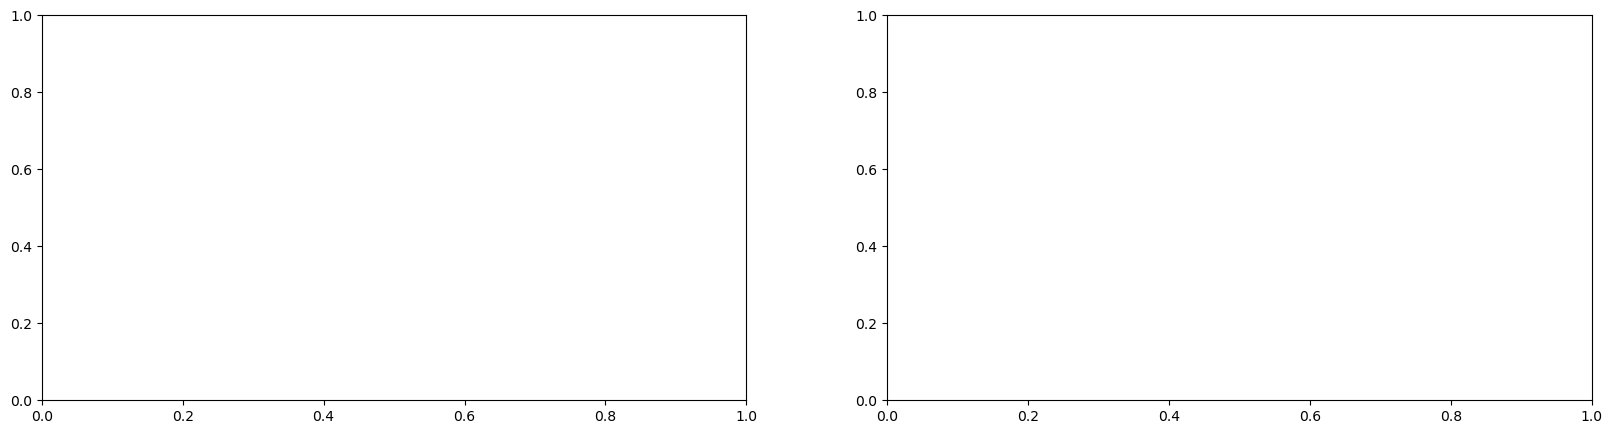

In [14]:
alerceAGN = alerceProbs[np.isin(alerceProbs["oid"], oid_lasairAGN)]
fig = plt.figure(figsize = (20, 5))
axs = fig.subplots(1, 2)

bins = np.arange(0, 1, 0.05)

axs[0].hist(alerceAGN["clf1_AGN"], bins = bins,
        histtype = "step", color = "black", linewidth = 3)
axs[1].hist(alerceAGN["clf3_AGN"], bins = bins,
        histtype = "step", color = "black", linewidth = 3)

axs[0].set_ylabel("Count", fontsize = 16)
axs[0].set_xlabel("Classifier 1", fontsize = 16)
axs[1].set_xlabel("Classifier 3", fontsize = 16)

# fig.supxlabel("Probability of ALeRCE classifying\nthe object as an AGN", y = -.05, fontsize = 16)